In [1]:
!pip -q install pandas numpy matplotlib seaborn plotly scikit-learn openpyxl xgboost joblib shap

In [2]:
import os
import warnings
import requests
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
from google.colab import files

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online Retail.xlsx"
FILE_PATH = "/content/Online Retail.xlsx"

try:
    response = requests.get(DATA_URL, timeout=120)
    response.raise_for_status()

    if not response.content.startswith(b"PK"):
        raise ValueError("Invalid Excel file received.")

    with open(FILE_PATH, "wb") as f:
        f.write(response.content)

    print("Dataset downloaded successfully.")

except Exception as error:
    print("Download failed:", error)
    print("Upload Online_Retail.xlsx manually.")

    uploaded = files.upload()
    excel_files = [
        name for name in uploaded
        if name.lower().endswith((".xlsx", ".xls"))
    ]

    if not excel_files:
        raise ValueError("No Excel dataset uploaded.")

    FILE_PATH = "/content/" + excel_files[0]



Dataset downloaded successfully.


In [5]:
df = pd.read_excel(FILE_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate records:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing values:


,Missing Values
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



Duplicate records: 5268

Statistical summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df.columns = df.columns.str.strip()

required = [
    "InvoiceNo", "StockCode", "Description",
    "Quantity", "InvoiceDate", "UnitPrice",
    "CustomerID", "Country"
]

missing = set(required) - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {missing}")

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

df = df.dropna(
    subset=["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"]
).copy()

cancelled = df["InvoiceNo"].astype(str).str.startswith("C")

df = df.loc[
    (~cancelled) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

df["Revenue"] = df["Quantity"] * df["UnitPrice"]
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["Revenue"])

print("Cleaned dataset shape:", df.shape)
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

display(df.head())

Cleaned dataset shape: (530104, 9)
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [8]:
total_revenue = df["Revenue"].sum()
total_orders = df["InvoiceNo"].nunique()
total_customers = df["CustomerID"].nunique()
total_products = df["StockCode"].nunique()
average_order_value = total_revenue / max(total_orders, 1)

kpis = pd.DataFrame({
    "Business KPI": [
        "Total Revenue",
        "Total Orders",
        "Unique Customers",
        "Unique Products",
        "Average Order Value"
    ],
    "Value": [
        round(total_revenue, 2),
        total_orders,
        total_customers,
        total_products,
        round(average_order_value, 2)
    ]
})

display(kpis)

,Business KPI,Value
0,Total Revenue,10666684.54
1,Total Orders,19960.00
2,Unique Customers,4338.00
3,Unique Products,3922.00
4,Average Order Value,534.40


In [9]:
monthly_sales = (
    df.set_index("InvoiceDate")["Revenue"]
      .resample("MS")
      .sum()
      .reset_index()
)

monthly_sales.columns = ["Month", "Revenue"]

fig = px.line(
    monthly_sales,
    x="Month",
    y="Revenue",
    markers=True,
    title="Monthly Revenue Trend"
)
fig.show()

In [10]:
top_products = (
    df.groupby("Description", observed=True)["Revenue"]
      .sum()
      .nlargest(10)
      .reset_index()
)

fig = px.bar(
    top_products,
    x="Revenue",
    y="Description",
    orientation="h",
    title="Top 10 Products by Revenue"
)

fig.update_layout(yaxis={"categoryorder": "total ascending"})
fig.show()

In [11]:
country_sales = (
    df.groupby("Country", observed=True)
      .agg(
          Revenue=("Revenue", "sum"),
          Orders=("InvoiceNo", "nunique")
      )
      .sort_values("Revenue", ascending=False)
      .head(15)
      .reset_index()
)

fig = px.bar(
    country_sales,
    x="Country",
    y="Revenue",
    title="Top 15 Countries by Revenue"
)
fig.show()

In [12]:
daily_sales = (
    df.set_index("InvoiceDate")["Revenue"]
      .resample("D")
      .sum()
      .asfreq("D", fill_value=0)
)

print("Daily records:", len(daily_sales))
display(daily_sales.head())

Daily records: 374


,Revenue
InvoiceDate,
2010-12-01,58960.79
2010-12-02,47748.38
2010-12-03,46943.71
2010-12-04,0.00
2010-12-05,31774.95


In [13]:
def create_features(series):
    data = pd.DataFrame(index=series.index)
    data["Sales"] = series

    for lag in [1, 2, 3, 7, 14, 28]:
        data[f"lag_{lag}"] = series.shift(lag)

    for window in [7, 14, 28]:
        shifted = series.shift(1)
        data[f"rolling_mean_{window}"] = shifted.rolling(window).mean()
        data[f"rolling_std_{window}"] = shifted.rolling(window).std()

    data["day_of_week"] = data.index.dayofweek
    data["day_of_month"] = data.index.day
    data["month"] = data.index.month
    data["quarter"] = data.index.quarter
    data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

    return data.dropna()


model_df = create_features(daily_sales)

feature_columns = [
    column for column in model_df.columns
    if column != "Sales"
]

X = model_df[feature_columns]
y = model_df["Sales"]

print("Feature shape:", X.shape)

Feature shape: (346, 17)


In [14]:
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

sales_model = XGBRegressor(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

sales_model.fit(X_train, y_train)

predictions = np.maximum(sales_model.predict(X_test), 0)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

wape = (
    np.abs(y_test.to_numpy() - predictions).sum()
    / max(np.abs(y_test.to_numpy()).sum(), 1e-9)
) * 100

forecast_metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2", "WAPE (%)"],
    "Value": [mae, rmse, r2, wape]
})

display(forecast_metrics)

,Metric,Value
0,MAE,16208.689291
1,RMSE,27016.175441
2,R2,0.267588
3,WAPE (%),34.348050


In [15]:
comparison = pd.DataFrame({
    "Date": y_test.index,
    "Actual Sales": y_test.values,
    "Predicted Sales": predictions
})

fig = px.line(
    comparison,
    x="Date",
    y=["Actual Sales", "Predicted Sales"],
    title="Actual vs Predicted Sales"
)
fig.show()

In [16]:
history = daily_sales.copy()
future_dates = pd.date_range(
    start=history.index.max() + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

future_values = []

for future_date in future_dates:
    extended = pd.concat([
        history,
        pd.Series([np.nan], index=[future_date])
    ])

    current_features = create_features(extended).iloc[[-1]][feature_columns]

    prediction = max(
        0,
        float(sales_model.predict(current_features)[0])
    )

    future_values.append(prediction)
    history.loc[future_date] = prediction

future_forecast = pd.DataFrame({
    "Date": future_dates,
    "Forecast Sales": future_values
})

display(future_forecast)

fig = px.line(
    future_forecast,
    x="Date",
    y="Forecast Sales",
    markers=True,
    title="30-Day Sales Forecast"
)
fig.show()


,Date,Forecast Sales
0,2011-12-10,41135.636719
1,2011-12-11,3172.217041
2,2011-12-12,32208.738281
3,2011-12-13,39132.871094
4,2011-12-14,46513.824219
5,2011-12-15,50495.613281
6,2011-12-16,49618.589844
7,2011-12-17,43764.089844
8,2011-12-18,16532.005859
9,2011-12-19,21238.943359


In [17]:
customer_df = df.dropna(subset=["CustomerID"]).copy()

reference_date = (
    customer_df["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

rfm = customer_df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x:
             (reference_date - x.max().normalize()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

rfm_features = np.log1p(
    rfm[["Recency", "Frequency", "Monetary"]].clip(lower=0)
)

scaler = StandardScaler()
scaled_rfm = scaler.fit_transform(rfm_features)

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Segment"] = kmeans.fit_predict(scaled_rfm)

segment_summary = rfm.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Orders=("Frequency", "mean"),
    Average_Spend=("Monetary", "mean"),
    Total_Spend=("Monetary", "sum")
).round(2)

display(segment_summary)

fig = px.scatter(
    rfm,
    x="Frequency",
    y="Monetary",
    color=rfm["Segment"].astype(str),
    hover_data=["CustomerID", "Recency"],
    title="Customer Segmentation"
)
fig.show()

,Customers,Average_Recency,Average_Orders,Average_Spend,Total_Spend
Segment,,,,,
0,877,20.56,2.05,527.17,462331.95
1,1579,187.68,1.33,352.13,556006.67
2,720,12.51,13.66,8037.21,5786787.92
3,1162,69.11,4.13,1812.63,2106281.36


In [18]:
anomaly_df = daily_sales.rename("Sales").to_frame()

anomaly_df["DayOfWeek"] = anomaly_df.index.dayofweek
anomaly_df["Month"] = anomaly_df.index.month

anomaly_model = IsolationForest(
    n_estimators=200,
    contamination=0.03,
    random_state=42
)

anomaly_df["Prediction"] = anomaly_model.fit_predict(
    anomaly_df[["Sales", "DayOfWeek", "Month"]]
)

anomaly_df["Status"] = np.where(
    anomaly_df["Prediction"] == -1,
    "Anomaly",
    "Normal"
)

display(
    anomaly_df[anomaly_df["Status"] == "Anomaly"]
    .sort_values("Sales", ascending=False)
    .head(20)
)

fig = px.scatter(
    anomaly_df.reset_index(),
    x="InvoiceDate",
    y="Sales",
    color="Status",
    title="Sales Anomaly Detection"
)
fig.show()

,Sales,DayOfWeek,Month,Prediction,Status
InvoiceDate,,,,,
2011-12-09,200920.60,4,12,-1,Anomaly
2011-11-14,114419.89,0,11,-1,Anomaly
2011-09-20,109612.03,1,9,-1,Anomaly
2010-12-07,99618.20,1,12,-1,Anomaly
2011-01-18,95978.05,1,1,-1,Anomaly
2011-12-05,88741.96,0,12,-1,Anomaly
2011-03-29,70711.92,1,3,-1,Anomaly
2011-01-11,68655.59,1,1,-1,Anomaly
2011-01-14,47576.90,4,1,-1,Anomaly


In [19]:
importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": sales_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance.head(15))

fig = px.bar(
    importance.head(15).sort_values("Importance"),
    x="Importance",
    y="Feature",
    orientation="h",
    title="Sales Forecast Feature Importance"
)
fig.show()

,Feature,Importance
16,is_weekend,0.464509
12,day_of_week,0.226688
3,lag_7,0.058136
14,month,0.027115
15,quarter,0.026998
6,rolling_mean_7,0.025504
10,rolling_mean_28,0.021841
7,rolling_std_7,0.021416
5,lag_28,0.019977
13,day_of_month,0.019737


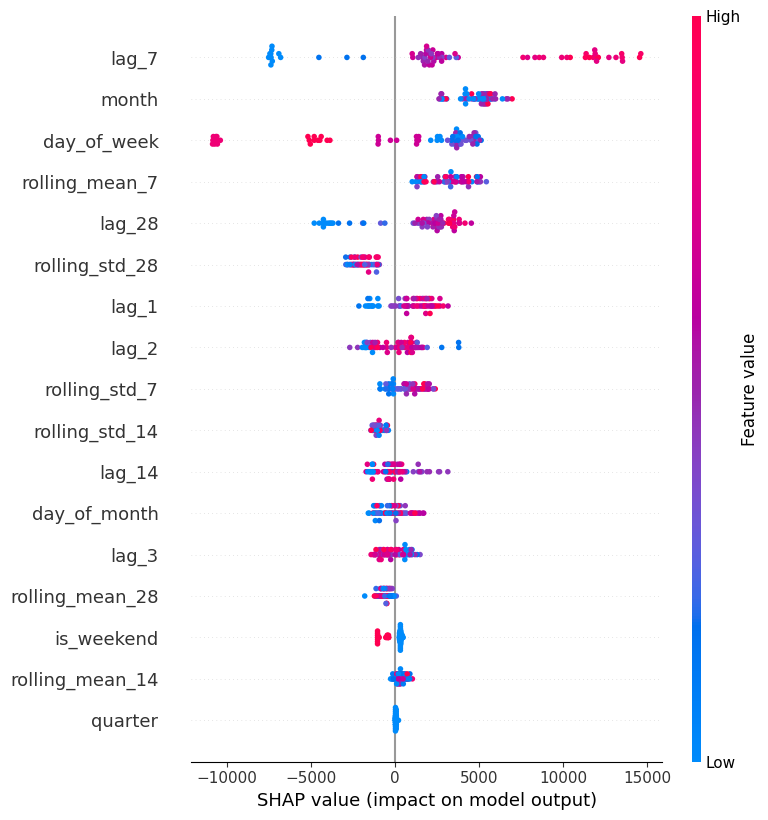

In [20]:
import shap

explainer = shap.TreeExplainer(sales_model)
shap_values = explainer(X_test)

shap.summary_plot(shap_values, X_test)

In [21]:
OUTPUT_DIR = "/content/business_intelligence_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

joblib.dump(
    sales_model,
    f"{OUTPUT_DIR}/sales_forecasting_model.pkl"
)

joblib.dump(
    scaler,
    f"{OUTPUT_DIR}/customer_scaler.pkl"
)

joblib.dump(
    kmeans,
    f"{OUTPUT_DIR}/customer_segmentation_model.pkl"
)

joblib.dump(
    anomaly_model,
    f"{OUTPUT_DIR}/anomaly_detection_model.pkl"
)

future_forecast.to_csv(
    f"{OUTPUT_DIR}/30_day_sales_forecast.csv",
    index=False
)

rfm.to_csv(
    f"{OUTPUT_DIR}/customer_segments.csv",
    index=False
)

anomaly_df.to_csv(
    f"{OUTPUT_DIR}/daily_sales_anomalies.csv"
)

forecast_metrics.to_csv(
    f"{OUTPUT_DIR}/forecast_metrics.csv",
    index=False
)

importance.to_csv(
    f"{OUTPUT_DIR}/feature_importance.csv",
    index=False
)

print("All models and outputs saved successfully!")
print("Output folder:", OUTPUT_DIR)

All models and outputs saved successfully!
Output folder: /content/business_intelligence_outputs


In [22]:
import shutil
from google.colab import files

ZIP_PATH = "/content/business_intelligence_outputs.zip"

shutil.make_archive(
    "/content/business_intelligence_outputs",
    "zip",
    OUTPUT_DIR
)

files.download(ZIP_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>